# 04 — Selección de variables

## Objetivo

Decidir con qué variables se entrenará el modelo. El cuadernillo 03 dejó 16 candidatas; aquí
se mide cuánto aporta cada una, cuáles dicen lo mismo que otra y cuáles no vale la pena
conservar. El resultado es una lista final, justificada variable por variable, que queda
guardada en `config/config.yaml` para que los cuadernillos de modelado la usen.

Criterios de decisión:

1. **Relación con el objetivo:** ¿la variable, por sí sola, separa ganadores de perdedores?
2. **Redundancia:** si dos variables están casi perfectamente correlacionadas, se conserva una.
3. **Cobertura:** ¿en cuántos mapas existe el dato?
4. **Aporte dentro de un modelo:** ¿empeora la predicción si se desordena esa variable?

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.config import CONFIG_PATH, PROCESSED_DIR, TABLES_DIR, load_config
from src.evaluation import evaluate, temporal_split
from src.features import FEATURES
from src.plotting import set_style, save_fig

set_style()
config = load_config()
TARGET = config["target"]
dataset = pd.read_csv(PROCESSED_DIR / "dataset.csv")

## 1. Partición temporal — y por qué se hace antes de mirar nada

El modelo se usará para predecir mapas futuros, así que debe evaluarse igual: entrenando con
el pasado y probando con lo que vino después. `temporal_split()` separa por año según `config.yaml`.

In [2]:
train, val, test = temporal_split(dataset, config["split"])
pd.DataFrame({
    "años": [config["split"][part] for part in ("train", "val", "test")],
    "mapas": [len(train), len(val), len(test)],
    "team_a_win": [part[TARGET].mean().round(3) for part in (train, val, test)],
}, index=["entrenamiento", "validación", "prueba"])

,años,mapas,team_a_win
entrenamiento,"[2021, 2022, 2023, 2024]",25210,0.501
validación,[2025],1272,0.498
prueba,[2026],886,0.503


**Todo este cuadernillo usa únicamente el conjunto de entrenamiento (2021–2024).** Elegir
variables mirando los datos de validación o prueba sería otra forma de fuga: las decisiones
quedarían ajustadas a los mismos datos con los que después se mide el modelo, y el resultado
final saldría optimista.

Cuando haga falta medir algo "fuera de muestra" dentro de este cuadernillo, se separa 2024
del resto del entrenamiento: se ajusta con 2021–2023 y se mide en 2024.

In [3]:
fit_part, check_part = train[train["year"] <= 2023], train[train["year"] == 2024]
print(len(fit_part), len(check_part))

24106 1104


## 2. Relación de cada variable con el objetivo

Para cada variable se calculan, sobre las filas donde existe:

- la **correlación** con `team_a_win`;
- el **AUC univariado**: la probabilidad de que, tomando un mapa ganado por Team A y uno
  perdido, la variable sea mayor en el ganado. 0.5 equivale a no saber nada; 1.0 sería
  separación perfecta;
- la proporción de **faltantes**.

In [4]:
rows = []
for feature in FEATURES:
    known = train[[feature, TARGET]].dropna()
    rows.append({
        "feature": feature,
        "corr": known[feature].corr(known[TARGET]),
        "auc": roc_auc_score(known[TARGET], known[feature]),
        "missing": train[feature].isna().mean(),
    })
univariate = pd.DataFrame(rows).set_index("feature").sort_values("auc", ascending=False)
univariate.round(3)

,corr,auc,missing
feature,,,
diff_maps_played,0.188,0.651,0.000
diff_round_diff,0.268,0.650,0.400
diff_winrate,0.253,0.643,0.400
diff_acs,0.247,0.639,0.400
diff_maps_played_map,0.182,0.637,0.000
diff_adr,0.231,0.628,0.406
diff_kast,0.227,0.624,0.548
diff_rating,0.221,0.619,0.548
h2h_winrate_a,0.200,0.614,0.810


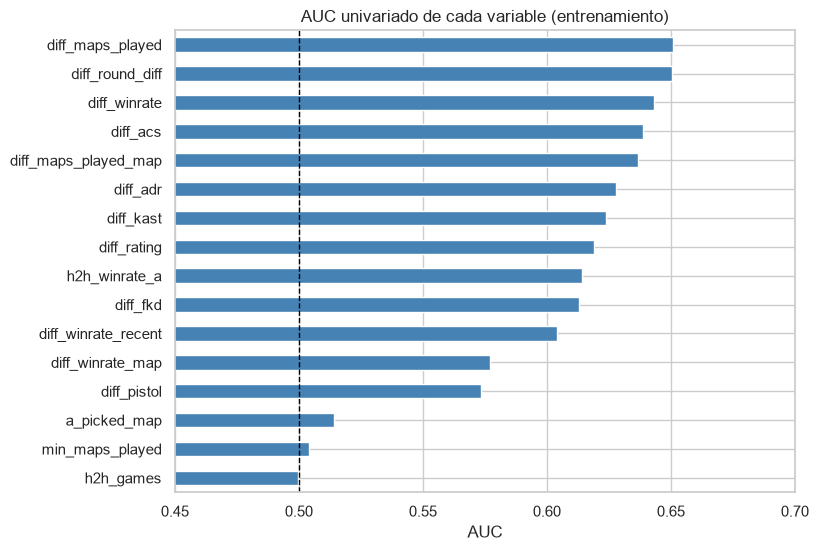

In [5]:
ax = univariate["auc"].sort_values().plot.barh(color="steelblue", figsize=(8, 6))
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.set(title="AUC univariado de cada variable (entrenamiento)", xlabel="AUC", ylabel="", xlim=(0.45, 0.70))
save_fig("04_auc_univariado")
plt.show()

- Las variables de rendimiento general (`diff_round_diff`, `diff_winrate`, `diff_acs`) y la de
  experiencia (`diff_maps_played`) son las más informativas, con AUC entre 0.64 y 0.65.
- **`diff_maps_played` es tan buena como el winrate.** Tiene sentido: los equipos que
  acumulan muchos mapas son los que avanzan en los torneos y los que se mantienen en el
  circuito, es decir, los mejores.
- `diff_winrate_recent` (últimos 10 mapas) rinde menos que el winrate de todo el historial:
  diez mapas son pocos y el resultado es más ruidoso.
- `min_maps_played` y `h2h_games` tienen AUC 0.5. Es lo esperado: no dicen *quién* es mejor
  (valen lo mismo si se intercambian los equipos), solo cuánta información hay. Su posible
  utilidad es como contexto para otras variables, no por sí solas.
- `a_picked_map` apenas se separa de 0.5.

Se revisa aparte `a_picked_map`, porque es la única variable que no depende del historial.

In [6]:
picked = train.dropna(subset=["a_picked_map"]).groupby("a_picked_map")[TARGET].agg(team_a_winrate="mean", maps="size")
picked.index = picked.index.map({-1.0: "Lo eligió Team B", 0.0: "Mapa decisivo", 1.0: "Lo eligió Team A"})
picked.round(3)

,team_a_winrate,maps
a_picked_map,,
Lo eligió Team B,0.487,3064
Mapa decisivo,0.477,990
Lo eligió Team A,0.516,3104


Elegir el mapa da una ventaja pequeña: quien lo elige gana cerca del 51.5 % de las veces.
Es poca señal, pero es información legítima y disponible antes del partido.

## 3. Redundancia entre variables

Muchas variables miden lo mismo desde ángulos distintos: un equipo que gana mucho también
tiene buen ACS, buen rating y buena diferencia de rondas. Variables casi idénticas no
aportan información nueva y vuelven inestables los coeficientes de un modelo lineal.

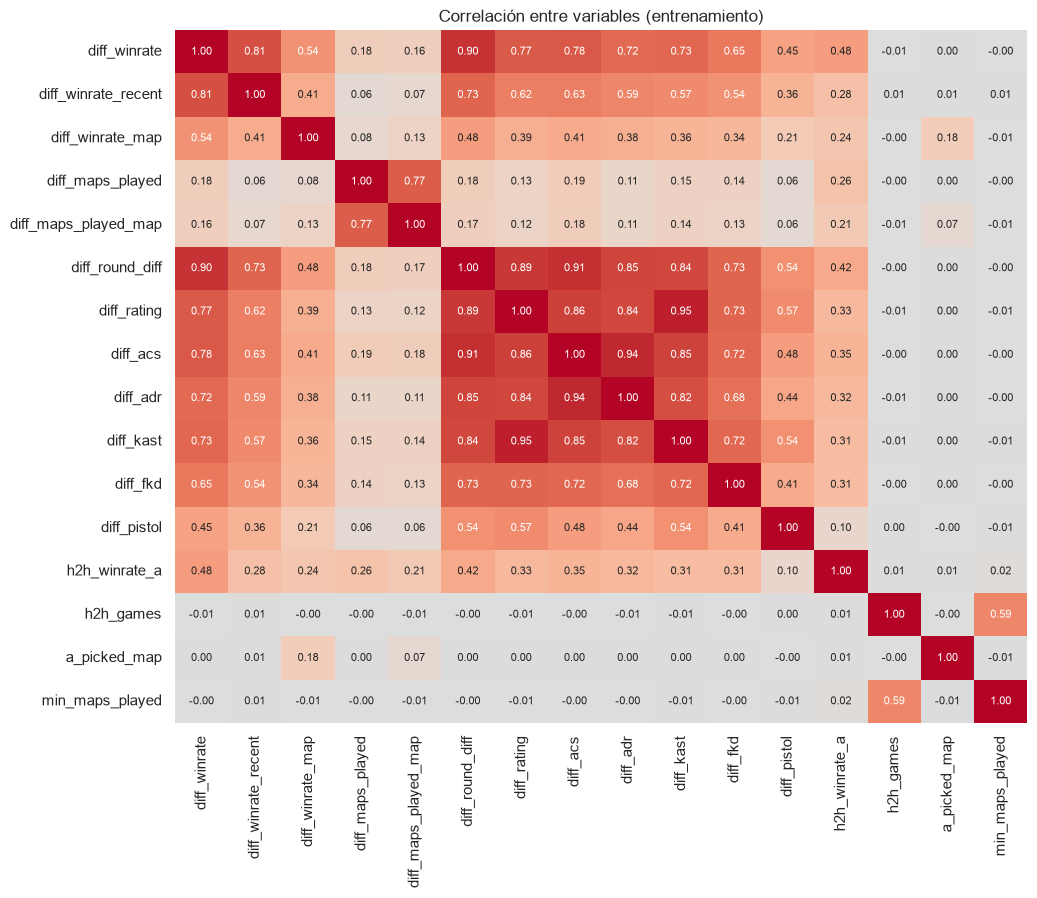

In [7]:
corr = train[FEATURES].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 8}, cbar=False)
plt.title("Correlación entre variables (entrenamiento)")
save_fig("04_correlacion_variables")
plt.show()

In [8]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() >= 0.75].sort_values(ascending=False).round(2).to_frame("correlación")

,,correlación
diff_rating,diff_kast,0.95
diff_acs,diff_adr,0.94
diff_round_diff,diff_acs,0.91
diff_winrate,diff_round_diff,0.90
diff_round_diff,diff_rating,0.89
diff_rating,diff_acs,0.86
diff_acs,diff_kast,0.85
diff_round_diff,diff_adr,0.85
diff_rating,diff_adr,0.84
diff_round_diff,diff_kast,0.84


Hay un bloque de variables de rendimiento muy correlacionadas entre sí. Los casos más claros:

- **`diff_rating` y `diff_kast` (0.95):** el *rating* de vlr.gg es una fórmula que ya
  incorpora el KAST. Tienen la misma cobertura; se conserva `diff_kast`, que es una
  estadística directa y con AUC ligeramente mayor, y se descarta `diff_rating`.
- **`diff_acs` y `diff_adr` (0.94):** el ACS se calcula sobre todo a partir del daño. Se
  conserva `diff_acs` (mayor AUC y menos faltantes) y se descarta `diff_adr`.
- **`diff_maps_played` y `diff_maps_played_map` (0.77):** la experiencia en un mapa concreto
  es casi una fracción de la experiencia total. Se conserva la general.
- **`diff_round_diff` con `diff_winrate` (0.90) y con `diff_acs` (0.91):** correlación alta,
  pero son conceptos distintos (margen de victoria, frecuencia de victoria, nivel individual)
  y las tres están entre las más informativas. Se conservan y se deja que el modelo reparta el peso.

## 4. Aporte dentro de un modelo: importancia por permutación

El análisis univariado mira cada variable aislada. Para ver su aporte *en conjunto*, se
entrena un modelo rápido (Gradient Boosting, que admite faltantes) con 2021–2023 y se mide en
2024 cuánto empeora su *log loss* al desordenar los valores de una variable. Si desordenarla
no cambia nada, el modelo no la necesitaba.

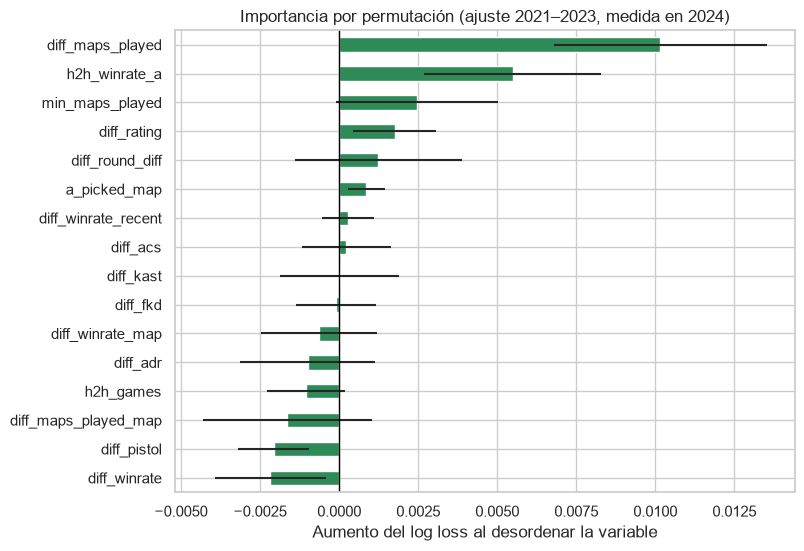

In [9]:
probe = HistGradientBoostingClassifier(random_state=config["seed"]).fit(fit_part[FEATURES], fit_part[TARGET])
importance = permutation_importance(probe, check_part[FEATURES], check_part[TARGET],
                                    scoring="neg_log_loss", n_repeats=30, random_state=config["seed"])
importance = pd.DataFrame({"mean": importance.importances_mean, "std": importance.importances_std},
                          index=FEATURES).sort_values("mean")

ax = importance["mean"].plot.barh(xerr=importance["std"], color="seagreen", figsize=(8, 6))
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Importancia por permutación (ajuste 2021–2023, medida en 2024)",
       xlabel="Aumento del log loss al desordenar la variable", ylabel="")
save_fig("04_importancia_permutacion")
plt.show()

Las variables redundantes aparecen con importancia cercana a cero o negativa: al desordenar
una, el modelo se apoya en su "gemela" y no pierde nada. Las barras de error son grandes
frente a los valores, así que este gráfico sirve para confirmar sospechas, no para ordenar
con precisión. Lo que sí muestra con claridad es que `diff_maps_played` y `h2h_winrate_a`
aportan información que las demás no tienen.

## 5. Decisión

Se aplica lo anterior a cada variable.

In [10]:
decisions = {
    "diff_winrate": ("conservar", "Señal alta; medida directa de qué tan seguido gana el equipo"),
    "diff_winrate_recent": ("conservar", "Única variable de forma reciente; capta rachas que el historial completo diluye"),
    "diff_winrate_map": ("conservar", "Única variable específica del mapa que se juega"),
    "diff_maps_played": ("conservar", "Mejor AUC univariado y mayor importancia por permutación; nunca falta"),
    "diff_maps_played_map": ("descartar", "Redundante con diff_maps_played (r = 0.77) y con menos señal"),
    "diff_round_diff": ("conservar", "Mayor correlación con el objetivo; mide el margen, no solo el resultado"),
    "diff_rating": ("descartar", "Redundante con diff_kast (r = 0.95); el rating es una fórmula derivada"),
    "diff_acs": ("conservar", "Mejor indicador del nivel individual; buena cobertura"),
    "diff_adr": ("descartar", "Redundante con diff_acs (r = 0.94), con menos señal y más faltantes"),
    "diff_kast": ("conservar", "Mide consistencia del equipo ronda a ronda; se prefiere al rating"),
    "diff_fkd": ("conservar", "Duelos de apertura: aspecto táctico distinto al resto"),
    "diff_pistol": ("descartar", "Señal baja (AUC 0.57), 55 % de faltantes y sin aporte en el modelo"),
    "h2h_winrate_a": ("conservar", "Poca cobertura, pero aporta información propia del enfrentamiento"),
    "h2h_games": ("descartar", "Sin señal propia; el faltante de h2h_winrate_a ya indica que no hay enfrentamientos previos"),
    "a_picked_map": ("conservar", "Señal pequeña pero legítima y conocida antes del partido; completa desde 2024"),
    "min_maps_played": ("conservar", "No indica quién gana, pero dice cuánta evidencia respalda a las demás variables"),
}
table = univariate.join(pd.DataFrame(decisions, index=["decision", "reason"]).T)
table.to_csv(TABLES_DIR / "04_variables.csv")
selected = [f for f in FEATURES if decisions[f][0] == "conservar"]
print(f"Se conservan {len(selected)} de {len(FEATURES)} variables")
table[["auc", "missing", "decision", "reason"]].round(3)

Se conservan 11 de 16 variables


,auc,missing,decision,reason
feature,,,,
diff_maps_played,0.651,0.000,conservar,Mejor AUC univariado y mayor importancia por p...
diff_round_diff,0.650,0.400,conservar,Mayor correlación con el objetivo; mide el mar...
diff_winrate,0.643,0.400,conservar,Señal alta; medida directa de qué tan seguido ...
diff_acs,0.639,0.400,conservar,Mejor indicador del nivel individual; buena co...
diff_maps_played_map,0.637,0.000,descartar,Redundante con diff_maps_played (r = 0.77) y c...
diff_adr,0.628,0.406,descartar,"Redundante con diff_acs (r = 0.94), con menos ..."
diff_kast,0.624,0.548,conservar,Mide consistencia del equipo ronda a ronda; se...
diff_rating,0.619,0.548,descartar,Redundante con diff_kast (r = 0.95); el rating...
h2h_winrate_a,0.614,0.810,conservar,"Poca cobertura, pero aporta información propia..."


## 6. ¿Se pierde algo al descartar?

Antes de fijar la lista se comprueba que el conjunto reducido predice igual de bien que el
completo. Se usan dos modelos de naturaleza distinta, ajustados con 2021–2023 y medidos en 2024.

In [11]:
def check(features):
    logistic = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                             LogisticRegression(max_iter=1000))
    boosting = HistGradientBoostingClassifier(random_state=config["seed"])
    results = {}
    for name, model in [("logistic", logistic), ("boosting", boosting)]:
        model.fit(fit_part[features], fit_part[TARGET])
        metrics = evaluate(check_part[TARGET], model.predict_proba(check_part[features])[:, 1])
        results.update({f"{name}_{k}": v for k, v in metrics.items()})
    return results

comparison = pd.DataFrame({f"todas ({len(FEATURES)})": check(FEATURES),
                           f"seleccionadas ({len(selected)})": check(selected)}).round(4)
comparison.to_csv(TABLES_DIR / "04_comparacion_conjuntos.csv")
comparison

,todas (16),seleccionadas (11)
logistic_accuracy,0.5788,0.5870
logistic_roc_auc,0.5964,0.5985
logistic_log_loss,0.7734,0.7870
boosting_accuracy,0.5661,0.5734
boosting_roc_auc,0.5860,0.5989
boosting_log_loss,0.6918,0.6835


El conjunto reducido no pierde capacidad de ordenar (el AUC se mantiene o mejora en ambos
modelos) con cinco variables menos.

Hay un dato que llama la atención: el *log loss* de la regresión logística (0.77–0.79) es
**peor que el de responder siempre 50 %** (0.693), aunque su exactitud y su AUC son
razonables. Significa que acierta el orden pero se pasa de confiada: asigna probabilidades
muy extremas y, cuando falla, la penalización es grande. Es un problema de calibración que se
aborda en el cuadernillo 05.

## 7. Guardar la lista final

In [12]:
config["features"] = selected
CONFIG_PATH.write_text(yaml.safe_dump(config, sort_keys=False, allow_unicode=True), encoding="utf-8")
load_config()["features"]

['diff_winrate',
 'diff_winrate_recent',
 'diff_winrate_map',
 'diff_maps_played',
 'diff_round_diff',
 'diff_acs',
 'diff_kast',
 'diff_fkd',
 'h2h_winrate_a',
 'a_picked_map',
 'min_maps_played']

## Conclusiones

1. **Lista final: 11 variables** de las 16 candidatas, guardadas en `config/config.yaml`:
   `diff_winrate`, `diff_winrate_recent`, `diff_winrate_map`, `diff_maps_played`,
   `diff_round_diff`, `diff_acs`, `diff_kast`, `diff_fkd`, `h2h_winrate_a`, `a_picked_map`
   y `min_maps_played`.
2. **Descartadas por redundancia:** `diff_rating` (r = 0.95 con `diff_kast`), `diff_adr`
   (r = 0.94 con `diff_acs`) y `diff_maps_played_map` (r = 0.77 con `diff_maps_played`).
3. **Descartadas por falta de señal:** `diff_pistol` (AUC 0.57 y 55 % de faltantes) y
   `h2h_games` (AUC 0.50).
4. **Las variables más informativas** son la experiencia (`diff_maps_played`, AUC 0.651), el
   margen de rondas (`diff_round_diff`, 0.650), el winrate (`diff_winrate`, 0.643) y el nivel
   individual (`diff_acs`, 0.639). Ninguna variable sola pasa de 0.65: la señal está repartida.
5. **Reducir no cuesta:** medido en 2024, el conjunto de 11 variables iguala o supera al de 16
   en AUC con ambos modelos de prueba (logística 0.599 vs 0.596; boosting 0.599 vs 0.586).
6. **Alerta para el modelado:** la regresión logística ordena bien pero está mal calibrada
   (log loss 0.79, peor que el 0.693 de no saber nada). Los modelos se entrenan sobre todo con
   partidos de 2021–2022, muy desiguales, y luego se aplican a ligas donde los equipos son
   parejos. Habrá que vigilar el log loss, no solo la exactitud.
7. **Toda la selección se hizo solo con el conjunto de entrenamiento**, para no contaminar la
   evaluación posterior.

**Siguiente paso (cuadernillo 05):** entrenar y comparar los modelos candidatos con estas 11 variables.